# Crop-Type Mapping of Godagari Upazila - Hybrid Pipeline

**Data engineering:**
* Expanded ground-truth QA (Dynamic World + duplicates + mixed-pixel + NDVI-profile checks)
* Regular 15-day median composites (Nov -> Apr), 12 indices
* B-spline functional smoothing
* FPCA scores as the classification features (best feature method in testing)

**Validation & reporting rigor:**
* FANOVA + FDR-corrected pairwise tests + Jeffries-Matusita separability
* Dual cross-validation: spatial-block AND leave-one-year-out
* Bootstrap 95% confidence intervals, McNemar significance tests, permutation importance
* Crop map + cultivated-area estimation

Target classes: Rice, Wheat, Lentil, Maize, Mustard, Potato.


# 0. IMPORTS

In [ ]:
pip install scikit-fda

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 488.6/488.6 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 64.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.4/50.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.6/44.6 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.7/287.7 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 6.0 MB/s eta 0:00:00


In [ ]:
import ee, geemap, json, os, warnings
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.signal import savgol_filter
from scipy.stats import chi2
from itertools import combinations
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (GroupKFold, LeaveOneGroupOut,
                                     cross_val_predict, GridSearchCV, GroupShuffleSplit)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, cohen_kappa_score,
                             confusion_matrix, classification_report)

try:
    from xgboost import XGBClassifier; HAS_XGB = True
except Exception:
    HAS_XGB = False; print('xgboost missing -> pip install xgboost')
try:
    from lightgbm import LGBMClassifier; HAS_LGB = True
except Exception:
    HAS_LGB = False; print('lightgbm missing -> pip install lightgbm')
try:
    import skfda
    from skfda.representation.grid import FDataGrid
    from skfda.representation.basis import BSplineBasis
    from skfda.preprocessing.dim_reduction import FPCA
    from skfda.inference.anova import oneway_anova
    HAS_SKFDA = True
except Exception as e:
    HAS_SKFDA = False; print('scikit-fda missing -> pip install scikit-fda (', e, ')')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
CROPS = ['Rice','Wheat','Lentil','Maize','Mustard','Potato']

# 1. AUTHENTICATE & REGION OF INTEREST

In [ ]:
ee.Authenticate()
ee.Initialize(project='ee-istiakasict')

In [ ]:
import subprocess
if not os.path.exists('gadm41_BGD_3.json'):
    subprocess.run(['curl','-O',
        'https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_BGD_3.json.zip'])
    subprocess.run(['unzip','-o','gadm41_BGD_3.json.zip'])
bd = gpd.read_file('gadm41_BGD_3.json')
roi_gdf = bd[(bd['NAME_2']=='Rajshahi') & (bd['NAME_3']=='Godagari')]
roi = geemap.gdf_to_ee(roi_gdf)
print('ROI area (ha):', round(roi.geometry().area().divide(1e4).getInfo(),1))

ROI area (ha): 49176.0


# 2. SEASON WINDOWS, INDEX SET & SENSOR FUNCTIONS

In [ ]:
SEASONS = {
    '2020_21': ('2020-11-01','2021-04-30'),
    '2021_22': ('2021-11-01','2022-04-30'),
    '2022_23': ('2022-11-01','2023-04-30'),
}
COMPOSITE_DAYS = 15   # 15-day median composites (>= S1 ~12-day revisit -> far fewer empty windows)
S2_INDICES = ['NDVI','EVI2','MSAVI','NDRE','GCVI','PSRI','LSWI','NDWI']
S1_INDICES = ['VV','VH','RVI','VH_VV']
ALL_INDICES = S2_INDICES + S1_INDICES
INDEX_RANGE = {'NDVI':(-1,1),'EVI2':(-1,1.5),'MSAVI':(-1,1.5),'NDRE':(-1,1),
               'GCVI':(0,12),'PSRI':(-1.5,1.5),'LSWI':(-1,1),'NDWI':(-1,1),
               'VV':(-30,5),'VH':(-35,0),'RVI':(0,1.5),'VH_VV':(0,2)}

In [ ]:
def mask_s2(img):
    scl = img.select('SCL')
    good = scl.remap([4,5,6,7],[1,1,1,1],0)
    qa = img.select('QA60')
    clear = qa.bitwiseAnd(1<<10).eq(0).And(qa.bitwiseAnd(1<<11).eq(0))
    return img.updateMask(good).updateMask(clear).divide(10000) \
              .copyProperties(img, ['system:time_start'])

def add_s2_indices(img):
    g=img.select('B3'); r=img.select('B4'); re1=img.select('B5')
    re2=img.select('B6'); nir=img.select('B8'); swir=img.select('B11')
    ndvi = nir.subtract(r).divide(nir.add(r)).clamp(-1,1).rename('NDVI')
    evi2 = nir.subtract(r).multiply(2.5).divide(nir.add(r.multiply(2.4)).add(1)).clamp(-1,1.5).rename('EVI2')
    a = nir.multiply(2).add(1)
    msavi = a.subtract(a.pow(2).subtract(nir.subtract(r).multiply(8)).sqrt()).divide(2).clamp(-1,1.5).rename('MSAVI')
    ndre = nir.subtract(re1).divide(nir.add(re1)).clamp(-1,1).rename('NDRE')
    gcvi = nir.divide(g).subtract(1).clamp(0,12).rename('GCVI')
    psri = r.subtract(g).divide(re2).clamp(-1.5,1.5).rename('PSRI')
    lswi = nir.subtract(swir).divide(nir.add(swir)).clamp(-1,1).rename('LSWI')
    ndwi = g.subtract(nir).divide(g.add(nir)).clamp(-1,1).rename('NDWI')
    return img.addBands([ndvi,evi2,msavi,ndre,gcvi,psri,lswi,ndwi])

def s2_collection(start,end):
    return (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
              .filterDate(start,end).filterBounds(roi)
              .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE',60))
              .map(mask_s2).map(add_s2_indices).select(S2_INDICES))

def s1_collection(start,end):
    s1 = (ee.ImageCollection('COPERNICUS/S1_GRD')
            .filterDate(start,end).filterBounds(roi)
            .filter(ee.Filter.eq('instrumentMode','IW'))
            .filter(ee.Filter.listContains('transmitterReceiverPolarisation','VV'))
            .filter(ee.Filter.listContains('transmitterReceiverPolarisation','VH'))
            .filter(ee.Filter.eq('orbitProperties_pass','DESCENDING'))
            .select(['VV','VH']))
    def proc(img):
        lin = ee.Image(10).pow(img.divide(10)); sm = lin.focal_mean(30,'circle','meters')
        vv=sm.select('VV'); vh=sm.select('VH')
        rvi = vh.multiply(4).divide(vv.add(vh)).clamp(0,1.5).rename('RVI')
        ratio = vh.divide(vv).clamp(0,2).rename('VH_VV')
        vv_db = ee.Image(10).multiply(vv.log10()).rename('VV')
        vh_db = ee.Image(10).multiply(vh.log10()).rename('VH')
        return ee.Image.cat([vv_db,vh_db,rvi,ratio]).copyProperties(img,['system:time_start'])
    return s1.map(proc).select(S1_INDICES)

def composite_series(coll, bands, start, end):
    start=ee.Date(start); end=ee.Date(end)
    n=end.difference(start,'day').divide(COMPOSITE_DAYS).floor()
    steps=ee.List.sequence(0,n.subtract(1))   # drop the short partial final window (stub)
    # masked placeholder so EMPTY 15-day windows still carry the expected band names
    empty=ee.Image.constant([0]*len(bands)).rename(bands).updateMask(ee.Image(0)).toFloat()
    def one(i):
        s=start.advance(ee.Number(i).multiply(COMPOSITE_DAYS),'day'); e=s.advance(COMPOSITE_DAYS,'day')
        sub=coll.filterDate(s,e).select(bands)
        comp=ee.Image(ee.Algorithms.If(sub.size().gt(0), sub.median(), empty))
        return comp.rename(bands).set('t_index',i).set('system:time_start',s.millis())
    return ee.ImageCollection(steps.map(one))

# 3. LOAD & MERGE 3 YEARS

In [ ]:
files = {'2020_21':'2020_21.csv','2021_22':'2021_22.csv','2022_23':'2022_23.csv'}
frames=[]
for yr,f in files.items():
    d=pd.read_csv(f); d['Year']=yr; frames.append(d)
pts = pd.concat(frames, ignore_index=True)
pts['Crop_name']=pts['Crop_name'].str.strip().str.title()
pts = pts[pts['Crop_name'].isin(CROPS+['Others'])].reset_index(drop=True)
pts['uid']=pts.index
print(pts['Crop_name'].value_counts()); print('Total:', len(pts))

Crop_name
Rice       484
Others     469
Mustard    288
Maize      187
Wheat      178
Lentil     124
Potato     114
Name: count, dtype: int64
Total: 1844


# 4. GROUND-TRUTH QUALITY ASSESSMENT

Four independent flags: Dynamic World non-crop / low crop-probability; duplicate coordinates;
mixed pixel (high local NDVI heterogeneity); and implausibly low peak NDVI.

In [ ]:
DW = ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1')
DW_CLASSES = ['water','trees','grass','flooded_vegetation','crops',
              'shrub_and_scrub','built','bare','snow_and_ice']
NONCROP_DW = {'water','built','snow_and_ice'}

def qa_metrics(df):
    out=[]
    for yr,sub in df.groupby('Year'):
        s,e=SEASONS[yr]
        fc=geemap.gdf_to_ee(gpd.GeoDataFrame(sub,
            geometry=gpd.points_from_xy(sub.longitude,sub.latitude),crs='EPSG:4326'))
        dw=DW.filterDate(s,e).filterBounds(roi)
        mode_lbl=dw.select('label').reduce(ee.Reducer.mode()).rename('dw_mode')
        crop_prob=dw.select('crops').mean().rename('dw_crop_prob')
        s2=s2_collection(s,e).select('NDVI')
        ndvi_max=s2.max().rename('ndvi_max')
        ndvi_het=s2.max().reduceNeighborhood(reducer=ee.Reducer.stdDev(),
                                              kernel=ee.Kernel.square(radius=30,units='meters')).rename('ndvi_het')
        img=mode_lbl.addBands([crop_prob,ndvi_max,ndvi_het])
        for ft in img.reduceRegions(fc,ee.Reducer.first(),10).getInfo()['features']:
            p=ft['properties']
            out.append({'uid':p['uid'],'dw_mode':p.get('dw_mode'),'dw_crop_prob':p.get('dw_crop_prob'),
                        'ndvi_max':p.get('ndvi_max'),'ndvi_het':p.get('ndvi_het')})
    r=pd.DataFrame(out)
    r['dw_mode_label']=r['dw_mode'].apply(
        lambda i: DW_CLASSES[int(i)] if i is not None and not (isinstance(i,float) and np.isnan(i)) else None)
    return r

pts = pts.merge(qa_metrics(pts), on='uid', how='left')
pts['coord_key']=(pts['latitude'].round(5).astype(str)+'_'+pts['longitude'].round(5).astype(str))
pts['flag_duplicate']=pts.duplicated(subset=['coord_key'],keep='first')
pts['flag_dw']      = pts['Crop_name'].isin(CROPS) & (pts['dw_mode_label'].isin(NONCROP_DW) | (pts['dw_crop_prob']<0.20))
pts['flag_lowndvi'] = pts['Crop_name'].isin(CROPS) & (pts['ndvi_max']<0.30)
pts['flag_mixed']   = pts['ndvi_het']>0.18
pts['flag_any']     = pts[['flag_dw','flag_duplicate','flag_lowndvi','flag_mixed']].any(axis=1)
print(pts[['flag_dw','flag_duplicate','flag_lowndvi','flag_mixed','flag_any']].sum())

flag_dw            70
flag_duplicate      9
flag_lowndvi        2
flag_mixed         58
flag_any          128
dtype: int64


In [ ]:
pts[pts['flag_any']].to_csv('hybrid_qc_flagged.csv', index=False)
clean = pts[(~pts['flag_any']) & (pts['Crop_name'].isin(CROPS))].reset_index(drop=True)
print('Clean points by crop:\n', clean['Crop_name'].value_counts())
print('\nBy year:\n', clean.groupby(['Year','Crop_name']).size().unstack(fill_value=0))

Clean points by crop:
 Crop_name
Rice       463
Mustard    267
Maize      176
Wheat      158
Lentil     116
Potato     110
Name: count, dtype: int64

By year:
 Crop_name  Lentil  Maize  Mustard  Potato  Rice  Wheat
Year                                                  
2020_21        45     83       22      44   174     43
2021_22        35     40       62      26   117     35
2022_23        36     53      183      40   172     80


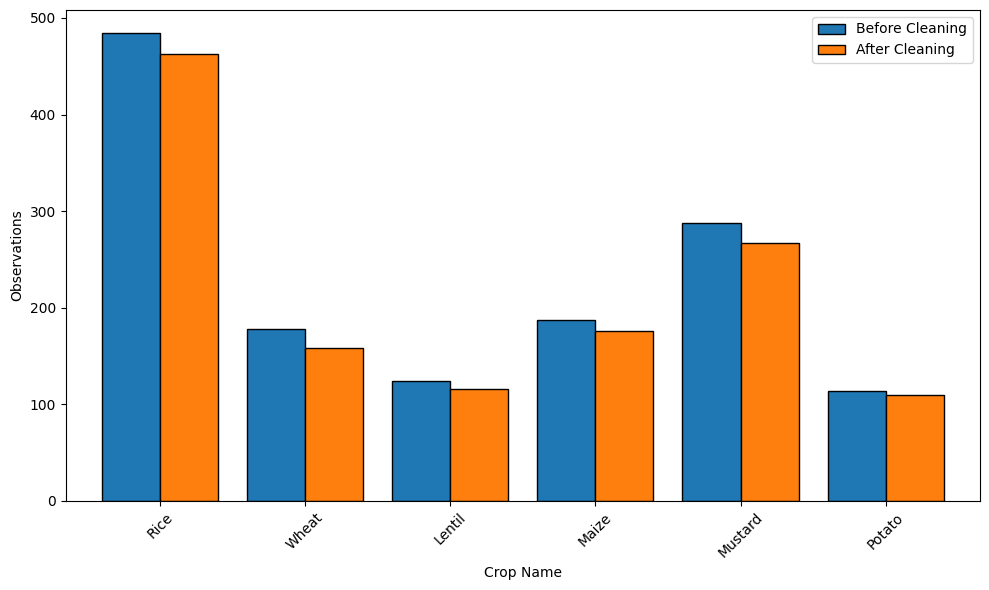

In [ ]:
before_counts = pts[pts['Crop_name'].isin(CROPS)]['Crop_name'].value_counts().reindex(CROPS)
after_counts = clean['Crop_name'].value_counts().reindex(CROPS)

comparison_df = pd.DataFrame({
    'Before Cleaning': before_counts,
    'After Cleaning': after_counts
})

fig, ax = plt.subplots(figsize=(10, 6))
comparison_df.plot.bar(ax=ax, edgecolor='k', width=0.8)

ax.set_xlabel('Crop Name')
ax.set_ylabel('Observations')
ax.tick_params(axis='x', rotation=45)
ax.legend();plt.tight_layout()
plt.savefig('data_cleaning.png',dpi=300,bbox_inches='tight'); plt.show()

# 5. EXTRACT 10-DAY TIME SERIES AT CLEAN POINTS

In [ ]:
def extract(yr, sub):
    s,e=SEASONS[yr]
    fc=geemap.gdf_to_ee(gpd.GeoDataFrame(sub,
        geometry=gpd.points_from_xy(sub.longitude,sub.latitude),crs='EPSG:4326'))
    s2c=composite_series(s2_collection(s,e),S2_INDICES,s,e)
    s1c=composite_series(s1_collection(s,e),S1_INDICES,s,e)
    def pull(coll,bands):
        size=coll.size().getInfo(); lst=coll.toList(size); rows=[]
        for i in range(size):
            im=ee.Image(lst.get(i)); ti=ee.Number(im.get('t_index')).getInfo()
            for ft in im.select(bands).reduceRegions(fc,ee.Reducer.mean(),15).getInfo()['features']:
                p=ft['properties']; rec={'uid':p['uid'],'t':int(ti)}
                for b in bands: rec[b]=p.get(b)
                rows.append(rec)
        return pd.DataFrame(rows)
    m=pd.merge(pull(s2c,S2_INDICES),pull(s1c,S1_INDICES),on=['uid','t'],how='outer'); m['Year']=yr
    return m

In [ ]:
ts=pd.concat([extract(yr,sub) for yr,sub in clean.groupby('Year')],ignore_index=True)
ts=ts.merge(clean[['uid','Crop_name','Year','latitude','longitude']].drop_duplicates('uid'),
            on=['uid','Year'],how='left')
ts.to_csv('hybrid_timeseries_15day.csv',index=False)
print('rows:',len(ts),'| points:',ts['uid'].nunique())

rows: 15480 | points: 1290


In [ ]:
# --- data-availability statistic (valid composite observations per point) ---
_nsteps = ts['t'].nunique()
_val = {s: ts.groupby('uid')[s].apply(lambda v: v.notna().sum())
        for s in ALL_INDICES}
print(f"\nTime steps per season (T): {_nsteps}")
print("Mean (min) valid observations per point:")
for _s in ALL_INDICES:
    _c = _val[_s]
    print(f"  {_s:6s} mean={_c.mean():4.1f}  min={int(_c.min()):2d}  median={int(_c.median()):2d}")
_s2 = pd.concat([_val[s] for s in S2_INDICES], axis=1).mean(axis=1)
_s1 = pd.concat([_val[s] for s in S1_INDICES], axis=1).mean(axis=1)
print(f"\nSentinel-2: mean {_s2.mean():.1f} valid obs/point (of {_nsteps})")
print(f"Sentinel-1: mean {_s1.mean():.1f} valid obs/point (of {_nsteps})")



Time steps per season (T): 12
Mean (min) valid observations per point:
  NDVI   mean=11.8  min=11  median=12
  EVI2   mean=11.8  min=11  median=12
  MSAVI  mean=11.8  min=11  median=12
  NDRE   mean=11.8  min=11  median=12
  GCVI   mean=11.8  min=11  median=12
  PSRI   mean=11.8  min=11  median=12
  LSWI   mean=11.8  min=11  median=12
  NDWI   mean=11.8  min=11  median=12
  VV     mean=11.6  min=11  median=12
  VH     mean=11.6  min=11  median=12
  RVI    mean=11.6  min=11  median=12
  VH_VV  mean=11.6  min=11  median=12

Sentinel-2: mean 11.8 valid obs/point (of 12)
Sentinel-1: mean 11.6 valid obs/point (of 12)


# 6. BUILD CURVES + B-SPLINE FUNCTIONAL SMOOTHING

In [ ]:
T = int(np.median(ts.groupby('uid')['t'].max())) + 1
GRID = np.arange(T)
print('time steps per season (T):', T)

uids=sorted(ts['uid'].unique())
curves_raw={idx:np.full((len(uids),T),np.nan) for idx in ALL_INDICES}
for k,u in enumerate(uids):
    g=ts[ts['uid']==u].sort_values('t')
    for idx in ALL_INDICES:
        lo,hi=INDEX_RANGE[idx]; tt=g['t'].values; vv=np.clip(g[idx].values.astype(float),lo,hi)
        ok=~np.isnan(vv)
        if ok.sum()>=2: curves_raw[idx][k]=np.interp(GRID,tt[ok],vv[ok],left=vv[ok][0],right=vv[ok][-1])
for idx in ALL_INDICES:
    cm=np.nanmean(curves_raw[idx],0); ii=np.where(np.isnan(curves_raw[idx])); curves_raw[idx][ii]=np.take(cm,ii[1])

y=np.array([clean.set_index('uid').loc[u,'Crop_name'] for u in uids])
groups=np.array([clean.set_index('uid').loc[u,'Year'] for u in uids])
le=LabelEncoder(); y_enc=le.fit_transform(y)

N_BASIS=8
def smooth(curves):
    out={}
    if HAS_SKFDA:
        basis=BSplineBasis(domain_range=(0,T-1),n_basis=N_BASIS,order=4)
        for idx in ALL_INDICES:
            out[idx]=FDataGrid(curves[idx],grid_points=GRID).to_basis(basis).to_grid(GRID).data_matrix[...,0]
    else:
        w=min(7,(T//2)*2+1)
        for idx in ALL_INDICES: out[idx]=np.vstack([savgol_filter(r,w,3) if T>=5 else r for r in curves[idx]])
    return out
curves=smooth(curves_raw)
print('smoothed curve matrix:', curves['NDVI'].shape)

time steps per season (T): 12
smoothed curve matrix: (1290, 12)


# 7. EDA - class balance & mean phenological curves

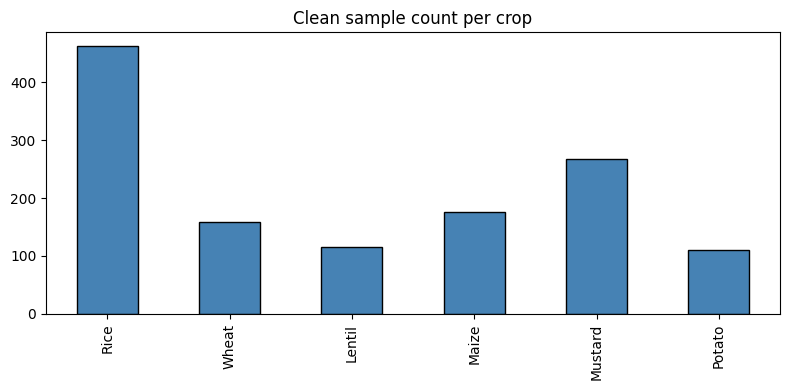

In [ ]:
palette=dict(zip(CROPS,sns.color_palette('tab10',len(CROPS))))
fig,ax=plt.subplots(figsize=(8,4))
pd.Series(y).value_counts().reindex(CROPS).plot.bar(ax=ax,color='steelblue',edgecolor='k')
ax.set_title('Clean sample count per crop'); plt.tight_layout()
plt.savefig('fig_class_balance.png',dpi=300,bbox_inches='tight'); plt.show()

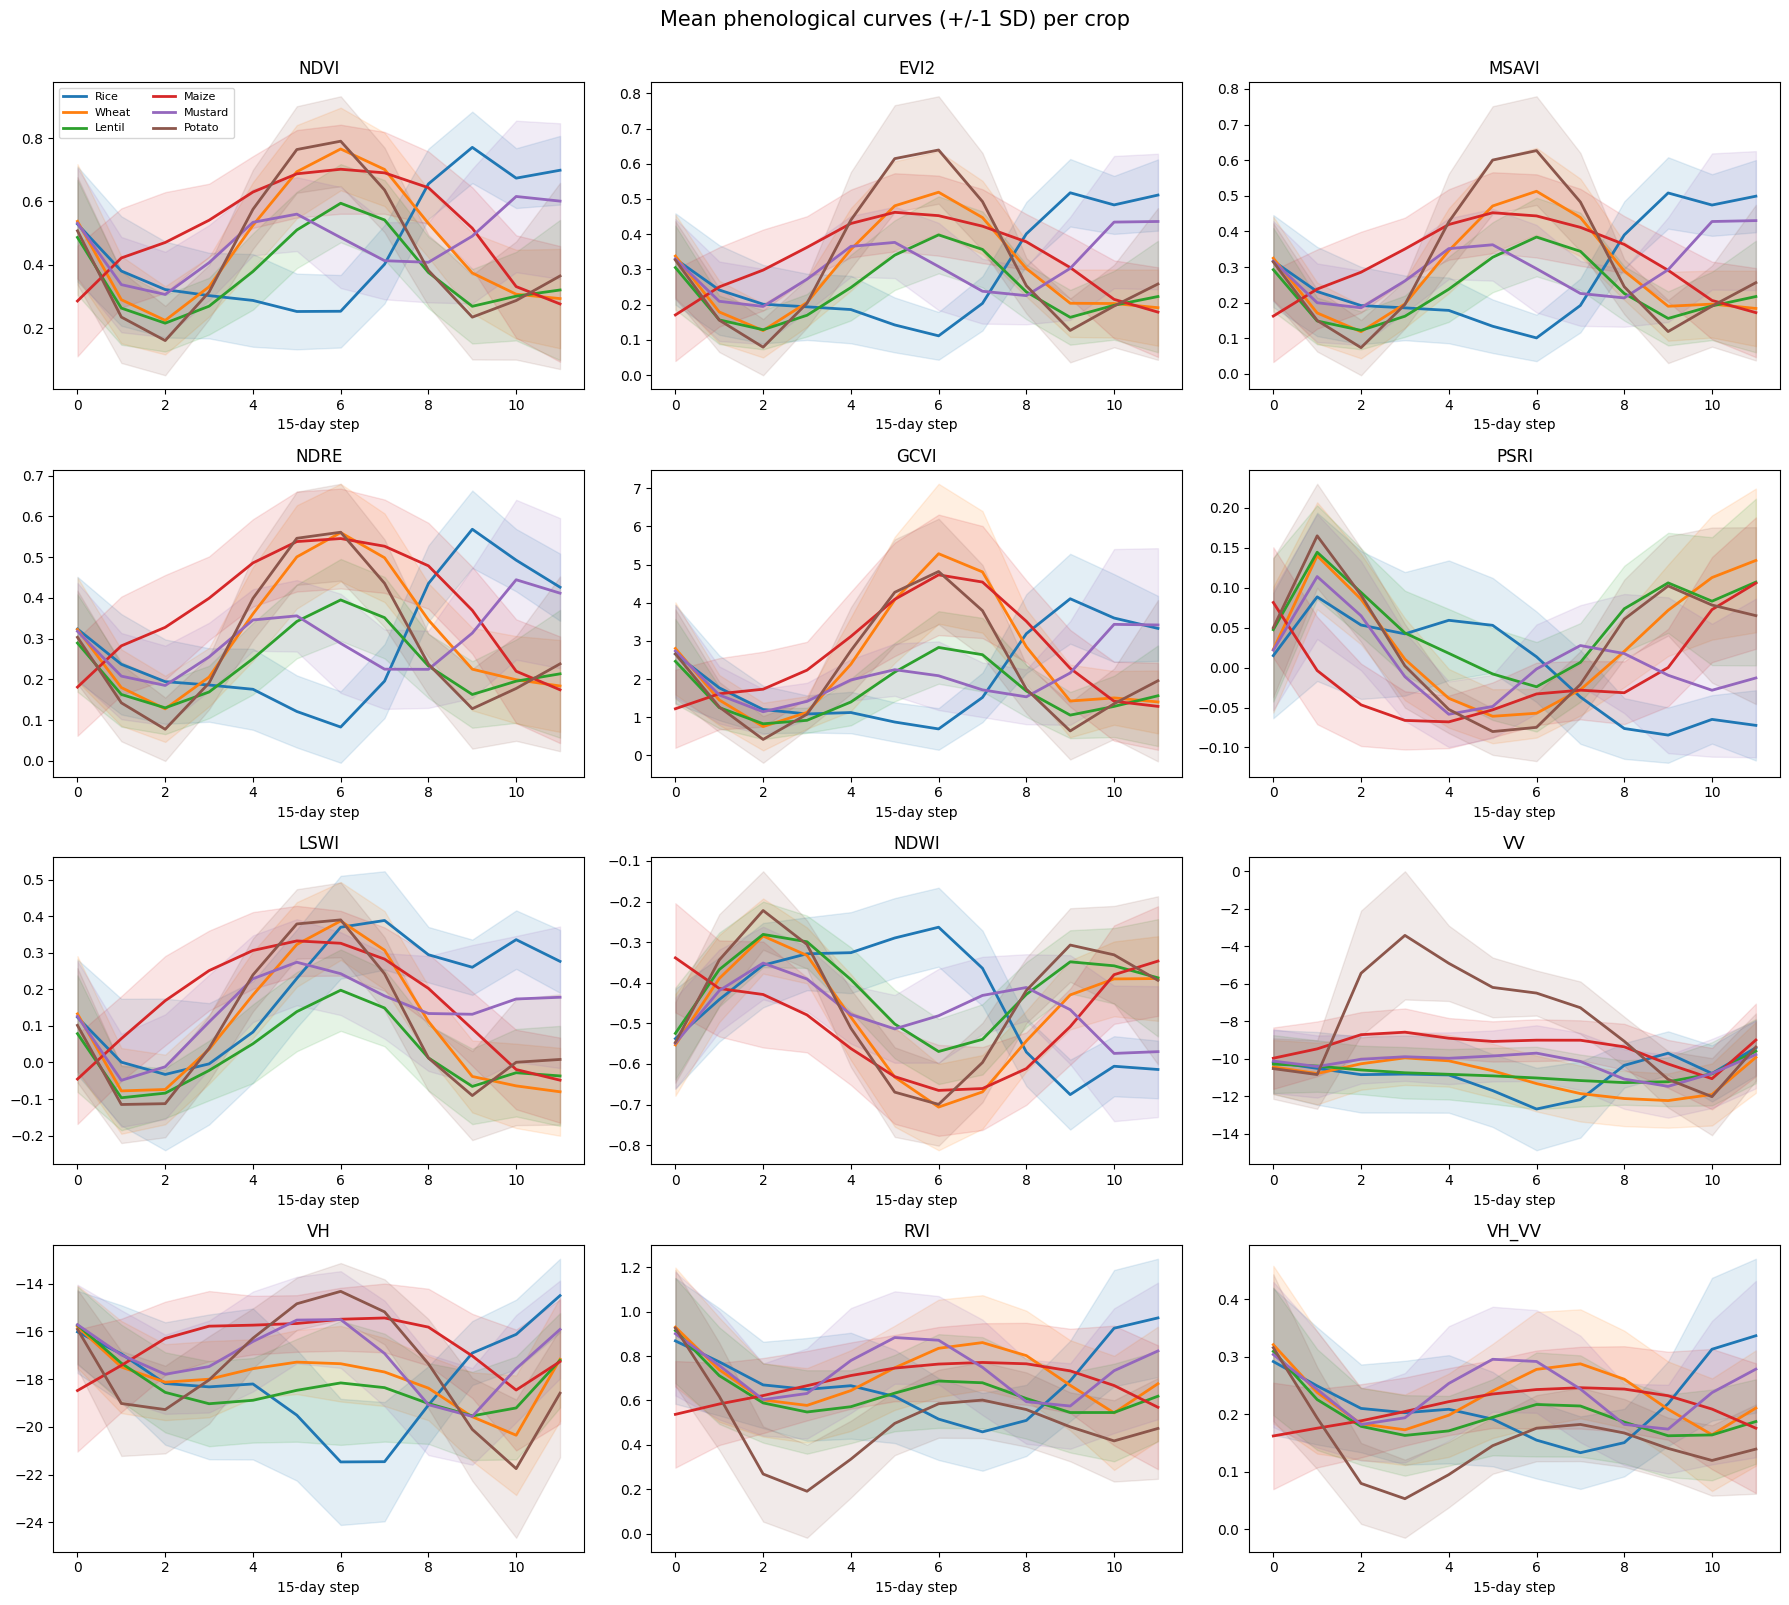

In [ ]:
fig,axes=plt.subplots(4,3,figsize=(18,16))
for ax,idx in zip(axes.ravel(),ALL_INDICES):
    for crop in CROPS:
        m=curves[idx][y==crop]; mu=m.mean(0); sd=m.std(0)
        ax.plot(GRID,mu,color=palette[crop],lw=2,label=crop)
        ax.fill_between(GRID,mu-sd,mu+sd,color=palette[crop],alpha=0.12)
    ax.set_title(idx); ax.set_xlabel('15-day step')
axes.ravel()[0].legend(fontsize=8,ncol=2)
fig.suptitle('Mean phenological curves (+/-1 SD) per crop',fontsize=15,y=1.0)
plt.tight_layout(); plt.savefig('fig_mean_curves.png',dpi=300,bbox_inches='tight'); plt.show()

# 8. FANOVA + FDR PAIRWISE TESTS + JEFFRIES-MATUSITA SEPARABILITY

              V_stat  p_value
NDVI     2534.509192      0.0
EVI2     1589.849222      0.0
MSAVI    1572.366239      0.0
NDRE     1860.547574      0.0
GCVI   124345.527655      0.0
PSRI      312.618923      0.0
LSWI     1156.711221      0.0
NDWI     1394.405429      0.0
VV     253871.202595      0.0
VH     289743.367967      0.0
RVI      1940.217576      0.0
VH_VV     266.022397      0.0


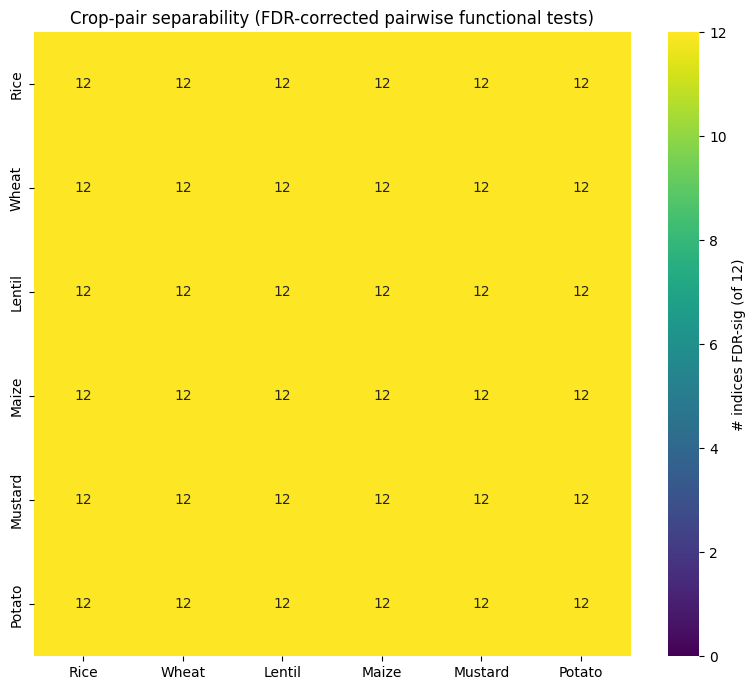

In [ ]:
def bh_fdr(p):
    p=np.asarray(p,float); n=len(p); order=np.argsort(p); adj=np.empty(n); prev=1.0
    for rank in range(n-1,-1,-1):
        i=order[rank]; prev=min(prev,p[i]*n/(rank+1)); adj[i]=prev
    return adj

if HAS_SKFDA:
    rows_f={}
    for idx in ALL_INDICES:
        fd=FDataGrid(curves[idx],grid_points=GRID)
        stat,pv=oneway_anova(*[fd[y==c] for c in CROPS],n_reps=500,random_state=RANDOM_STATE)
        rows_f[idx]={'V_stat':float(stat),'p_value':float(pv)}
    fanova_df=pd.DataFrame(rows_f).T.sort_values('p_value'); print(fanova_df)
    fanova_df.to_csv('hybrid_fanova.csv')

    PAIRS=list(combinations(CROPS,2)); sep=np.zeros((len(CROPS),len(CROPS)),int)
    for idx in ALL_INDICES:
        fd=FDataGrid(curves[idx],grid_points=GRID)
        raw=[oneway_anova(fd[y==a],fd[y==b],n_reps=200,random_state=RANDOM_STATE)[1] for a,b in PAIRS]
        for (a,b),pv in zip(PAIRS,bh_fdr(raw)):
            if pv<0.05:
                i,j=CROPS.index(a),CROPS.index(b); sep[i,j]+=1; sep[j,i]+=1
    np.fill_diagonal(sep,len(ALL_INDICES))
    plt.figure(figsize=(8,7))
    sns.heatmap(pd.DataFrame(sep,index=CROPS,columns=CROPS),annot=True,cmap='viridis',
                vmin=0,vmax=len(ALL_INDICES),cbar_kws={'label':f'# indices FDR-sig (of {len(ALL_INDICES)})'})
    plt.title('Crop-pair separability (FDR-corrected pairwise functional tests)')
    plt.tight_layout(); plt.savefig('fig_pairwise_fdr.png',dpi=300,bbox_inches='tight'); plt.show()

In [ ]:
from sklearn.covariance import LedoitWolf
# Jeffries-Matusita separability on FPCA feature space (computed in next cell's X)
# placeholder; JM uses X built in section 9
print('JM separability is computed after FPCA features are built (section 9).')

JM separability is computed after FPCA features are built (section 9).


# 9. FPCA FEATURE EXTRACTION (best feature method)

First 5 functional principal components per index -> compact, denoised feature matrix.

In [ ]:
N_FPCA=5
def build_fpca(curves_dict, fit_on=None):
    feats=[]; names=[]; idxlab=[]; explained_variance = {}
    for idx in ALL_INDICES:
        fd=FDataGrid(np.nan_to_num(curves_dict[idx]),grid_points=GRID)
        model=FPCA(n_components=N_FPCA).fit(fd)
        feats.append(model.transform(fd));
        names+=[f'{idx}_fpc{k+1}' for k in range(N_FPCA)]; idxlab+=[idx]*N_FPCA
        explained_variance[idx] = model.explained_variance_ratio_
    return np.hstack(feats), names, idxlab, explained_variance

if HAS_SKFDA:
    X, feat_names, feat_index, explained_variance_ratios = build_fpca(curves)
else:
    # fallback: phenometrics if skfda unavailable
    def pheno(a):
        mx=a.max(1); mn=a.min(1)
        return np.column_stack([a.mean(1),mx,mn,mx-mn,a.sum(1),GRID[a.argmax(1)]])
    X=np.hstack([pheno(curves[idx]) for idx in ALL_INDICES])
    feat_names=[f'{idx}_m{k}' for idx in ALL_INDICES for _ in range(6)]
    feat_index=[idx for idx in ALL_INDICES for _ in range(6)]
    explained_variance_ratios = None
print('FPCA feature matrix:', X.shape)

if explained_variance_ratios:
    print('\nExplained Variance Ratio for each index:')
    for idx, evr in explained_variance_ratios.items():
        print(f'  {idx}: {evr.round(3)}')


FPCA feature matrix: (1290, 60)

Explained Variance Ratio for each index:
  NDVI: [0.559 0.172 0.105 0.083 0.048]
  EVI2: [0.605 0.146 0.092 0.079 0.044]
  MSAVI: [0.608 0.141 0.092 0.08  0.044]
  NDRE: [0.599 0.163 0.109 0.063 0.04 ]
  GCVI: [0.609 0.149 0.101 0.054 0.044]
  PSRI: [0.407 0.302 0.105 0.085 0.052]
  LSWI: [0.394 0.265 0.171 0.087 0.042]
  NDWI: [0.587 0.142 0.108 0.07  0.055]
  VV: [0.568 0.123 0.101 0.08  0.053]
  VH: [0.464 0.219 0.12  0.066 0.062]
  RVI: [0.271 0.253 0.138 0.113 0.085]
  VH_VV: [0.263 0.232 0.144 0.116 0.083]


In [ ]:
if explained_variance_ratios:
    summed_evr = {idx: sum(evr) for idx, evr in explained_variance_ratios.items()}
    print('\nSummed Explained Variance Ratio for each index:')
    for idx, s_evr in summed_evr.items():
        print(f'  {idx}: {s_evr:.3f}')

    avg_summed_evr = np.mean(list(summed_evr.values()))
    median_summed_evr = np.median(list(summed_evr.values()))

    print(f'\nAverage of summed explained variance ratios across all indices: {avg_summed_evr:.3f}')
    print(f'Median of summed explained variance ratios across all indices: {median_summed_evr:.3f}')


Summed Explained Variance Ratio for each index:
  NDVI: 0.967
  EVI2: 0.966
  MSAVI: 0.965
  NDRE: 0.973
  GCVI: 0.958
  PSRI: 0.951
  LSWI: 0.959
  NDWI: 0.962
  VV: 0.925
  VH: 0.932
  RVI: 0.860
  VH_VV: 0.837

Average of summed explained variance ratios across all indices: 0.938
Median of summed explained variance ratios across all indices: 0.958


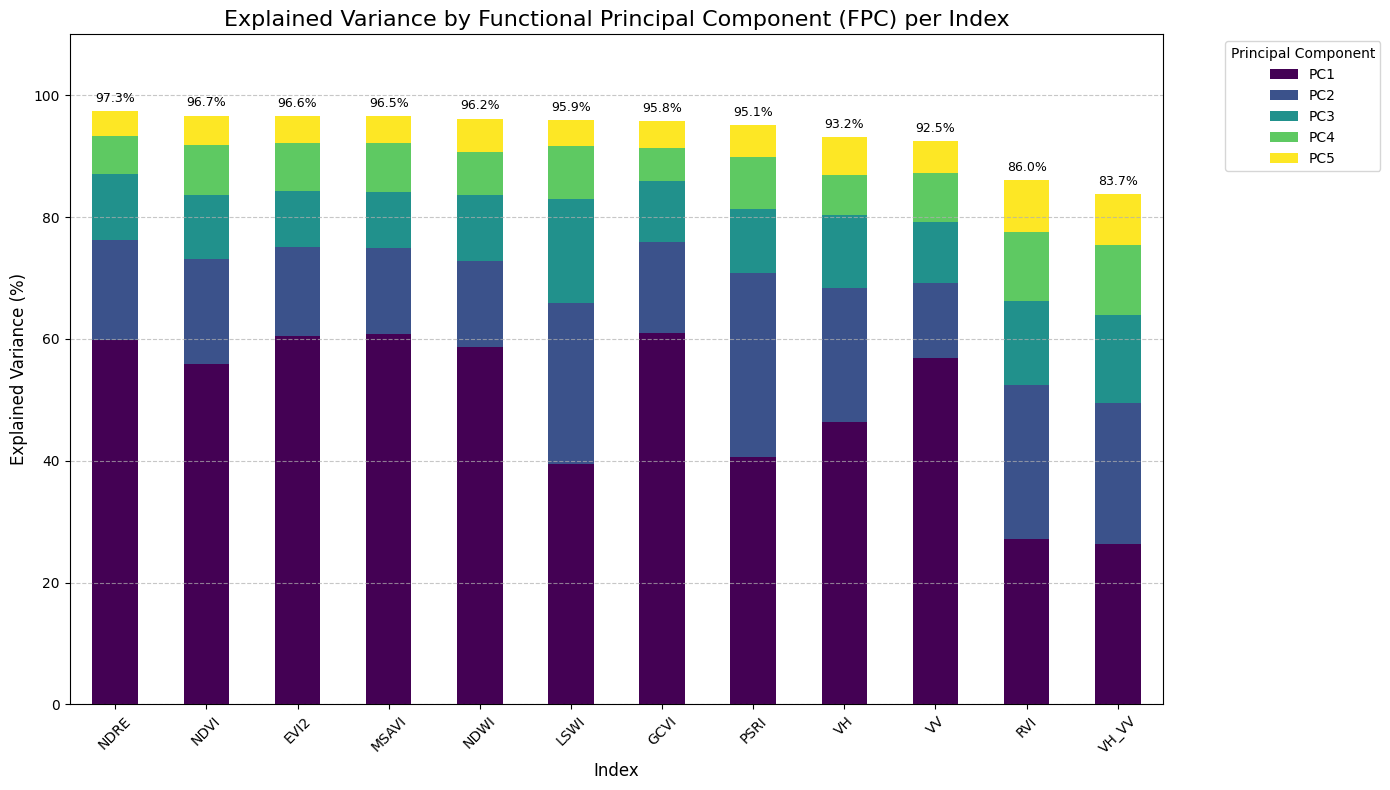

In [ ]:
if explained_variance_ratios:
    # Prepare data for plotting
    plot_data = []
    for idx, evr in explained_variance_ratios.items():
        row = {'Index': idx}
        for i, val in enumerate(evr):
            row[f'PC{i+1}'] = val * 100 # Convert to percentage
        plot_data.append(row)

    df_evr = pd.DataFrame(plot_data)
    df_evr = df_evr.set_index('Index')

    # Calculate cumulative explained variance
    df_evr['Cumulative'] = df_evr.sum(axis=1)

    # Sort by cumulative explained variance for better visualization
    df_evr_sorted = df_evr.sort_values(by='Cumulative', ascending=False)

    # Create the stacked bar chart
    fig, ax = plt.subplots(figsize=(14, 8))

    # Plot individual PC contributions
    df_evr_sorted[[f'PC{i+1}' for i in range(N_FPCA)]].plot(kind='bar', stacked=True, ax=ax, cmap='viridis')

    # Add cumulative sum labels on top of each bar
    for i, (index, row) in enumerate(df_evr_sorted.iterrows()):
        ax.text(i, row['Cumulative'] + 1, f'{row["Cumulative"]:.1f}%', ha='center', va='bottom', fontsize=9)

    ax.set_title('Explained Variance by Functional Principal Component (FPC) per Index', fontsize=16)
    ax.set_xlabel('Index', fontsize=12)
    ax.set_ylabel('Explained Variance (%)', fontsize=12)
    ax.set_ylim(0, 110) # Adjust y-limit to fit cumulative labels
    ax.tick_params(axis='x', rotation=45)
    ax.legend(title='Principal Component', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(axis='y', linestyle='--', alpha=0.7);plt.tight_layout()
    plt.savefig('PC_variance_explained.png',dpi=300,bbox_inches='tight'); plt.show()

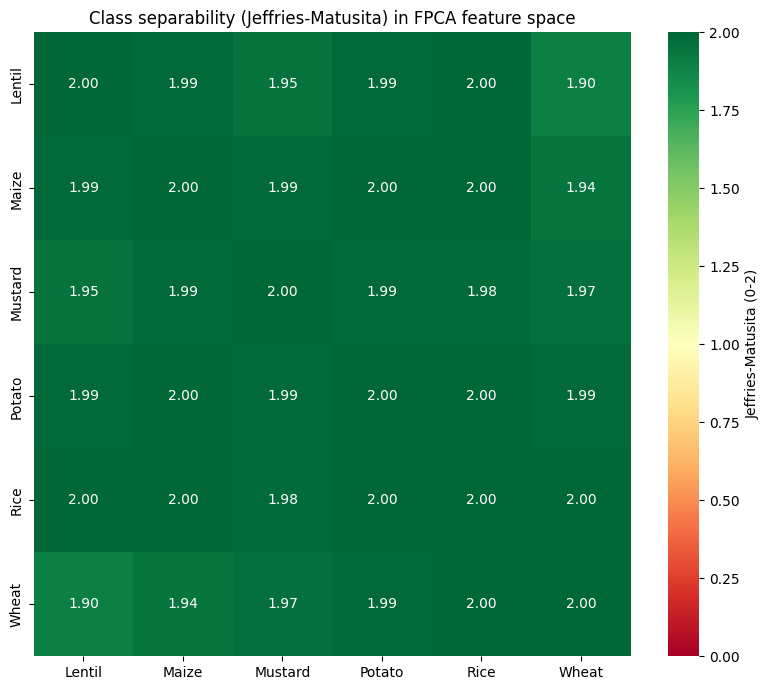

In [ ]:
# Jeffries-Matusita separability in the FPCA feature space
Xs=StandardScaler().fit_transform(X)
def bhatt(A,B):
    ma,mb=A.mean(0),B.mean(0); Sa=LedoitWolf().fit(A).covariance_; Sb=LedoitWolf().fit(B).covariance_
    S=(Sa+Sb)/2; d=ma-mb; t1=0.125*d@np.linalg.pinv(S)@d
    (_,lS),(_,lA),(_,lB)=np.linalg.slogdet(S),np.linalg.slogdet(Sa),np.linalg.slogdet(Sb)
    return t1+0.5*(lS-0.5*(lA+lB))
n=len(le.classes_); JM=np.full((n,n),2.0)
for i in range(n):
    for j in range(i+1,n):
        B=max(bhatt(Xs[y_enc==i],Xs[y_enc==j]),0); JM[i,j]=JM[j,i]=2*(1-np.exp(-B))
plt.figure(figsize=(8,7))
sns.heatmap(pd.DataFrame(JM,index=le.classes_,columns=le.classes_),annot=True,fmt='.2f',
            cmap='RdYlGn',vmin=0,vmax=2,cbar_kws={'label':'Jeffries-Matusita (0-2)'})
plt.title('Class separability (Jeffries-Matusita) in FPCA feature space')
plt.tight_layout(); plt.savefig('fig_jm_separability.png',dpi=300,bbox_inches='tight'); plt.show()
pd.DataFrame(JM,index=le.classes_,columns=le.classes_).round(3).to_csv('hybrid_jm.csv')

# 10. CLASSIFIER COMPARISON - DUAL CROSS-VALIDATION

Every model is evaluated under BOTH spatial-block CV (honest spatial estimate) and
leave-one-year-out CV (temporal-transfer stress test).

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
def models_factory():
    m={'Random Forest':RandomForestClassifier(n_estimators=400,class_weight='balanced',
            random_state=RANDOM_STATE,n_jobs=-1),
       'SVM (RBF)':Pipeline([('sc',StandardScaler()),
            ('svm',SVC(kernel='rbf',C=10,gamma='scale',class_weight='balanced',
                       probability=True,random_state=RANDOM_STATE))]),
       'k-NN':Pipeline([('sc',StandardScaler()),('knn',KNeighborsClassifier(7))])}
    if HAS_XGB: m['XGBoost']=XGBClassifier(n_estimators=400,max_depth=5,learning_rate=0.05,
            subsample=0.8,colsample_bytree=0.8,tree_method='hist',eval_metric='mlogloss',
            random_state=RANDOM_STATE)
    if HAS_LGB: m['LightGBM']=LGBMClassifier(n_estimators=400,learning_rate=0.05,
            class_weight='balanced',random_state=RANDOM_STATE,verbose=-1)
    return m

cell=(np.floor(clean.set_index('uid').loc[uids,['latitude','longitude']]/0.02)*0.02)
spatial_groups=(cell['latitude'].astype(str)+'_'+cell['longitude'].astype(str)).values

def eval_cv(name,clf,groups_,scheme):
    gkf=GroupKFold(n_splits=min(len(np.unique(groups_)),5))
    yp=cross_val_predict(clf,X,y_enc,cv=gkf,groups=groups_,n_jobs=-1)
    acc=accuracy_score(y_enc,yp); f1=f1_score(y_enc,yp,average='macro'); k=cohen_kappa_score(y_enc,yp)
    print(f'  [{scheme:7s}] {name:14s} acc={acc:.3f} macroF1={f1:.3f} kappa={k:.3f}')
    return {'model':name,'scheme':scheme,'acc':acc,'macroF1':f1,'kappa':k,'pred':yp}

rows=[]
print('--- Spatial-block CV ---')
for nme,c in models_factory().items(): rows.append(eval_cv(nme,c,spatial_groups,'Spatial'))
print('--- Leave-one-year-out CV ---')
for nme,c in models_factory().items(): rows.append(eval_cv(nme,c,groups,'LOYO'))
cmp_df=pd.DataFrame([{k:r[k] for k in ['model','scheme','acc','macroF1','kappa']} for r in rows])
print(); print(cmp_df.sort_values('macroF1',ascending=False).to_string(index=False))
cmp_df.to_csv('hybrid_model_comparison.csv',index=False)

--- Spatial-block CV ---
  [Spatial] Random Forest  acc=0.860 macroF1=0.837 kappa=0.819
  [Spatial] SVM (RBF)      acc=0.852 macroF1=0.828 kappa=0.810
  [Spatial] k-NN           acc=0.840 macroF1=0.817 kappa=0.795
  [Spatial] XGBoost        acc=0.861 macroF1=0.838 kappa=0.822
  [Spatial] LightGBM       acc=0.862 macroF1=0.841 kappa=0.823
--- Leave-one-year-out CV ---
  [LOYO   ] Random Forest  acc=0.792 macroF1=0.771 kappa=0.733
  [LOYO   ] SVM (RBF)      acc=0.769 macroF1=0.738 kappa=0.705
  [LOYO   ] k-NN           acc=0.801 macroF1=0.780 kappa=0.744
  [LOYO   ] XGBoost        acc=0.804 macroF1=0.776 kappa=0.748
  [LOYO   ] LightGBM       acc=0.805 macroF1=0.780 kappa=0.749

        model  scheme      acc  macroF1    kappa
     LightGBM Spatial 0.862016 0.840524 0.822722
      XGBoost Spatial 0.861240 0.837730 0.821616
Random Forest Spatial 0.859690 0.837374 0.819232
    SVM (RBF) Spatial 0.851938 0.828112 0.810131
         k-NN Spatial 0.840310 0.816501 0.794526
     LightGBM    LOY

# 11. ACCURACY ASSESSMENT (best spatial-CV model) + bootstrap CIs

Selected model: LightGBM | mean(spatial,LOYO) OA = 0.810 | spatial OA = 0.841
Ranking: [('LightGBM', 0.81), ('XGBoost', 0.807), ('Random Forest', 0.804), ('k-NN', 0.798), ('SVM (RBF)', 0.783)]


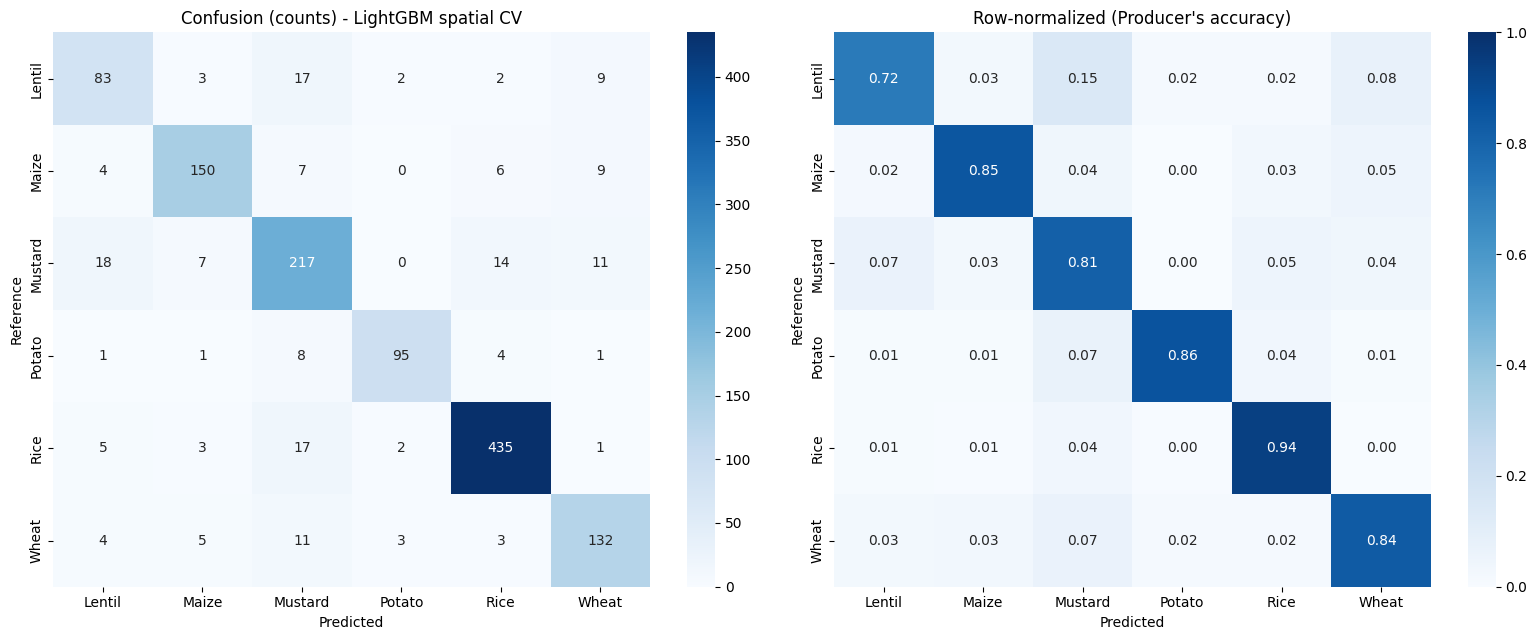

         Support  Producer's_Acc  User's_Acc     F1
Lentil       116           0.716       0.722  0.719
Maize        176           0.852       0.888  0.870
Mustard      267           0.813       0.783  0.798
Potato       110           0.864       0.931  0.896
Rice         463           0.940       0.938  0.939
Wheat        158           0.835       0.810  0.822

Model: LightGBM (spatial CV)
Overall Accuracy : 0.862  95% CI [0.843, 0.881]
Cohen's Kappa    : 0.823  95% CI [0.797, 0.846]
Macro F1         : 0.841  95% CI [0.817, 0.862]


In [ ]:
# --- model selection: primary = mean(spatial OA, LOYO OA); tie-break = spatial OA ---
def _sel_score(model):
    sp=[r for r in rows if r['model']==model and r['scheme']=='Spatial'][0]
    lo=[r for r in rows if r['model']==model and r['scheme']=='LOYO'][0]
    return ((sp['macroF1']+lo['macroF1'])/2.0, sp['macroF1'])
_ranked=sorted({r['model'] for r in rows}, key=_sel_score, reverse=True)
BEST_MODEL=_ranked[0]
print('Selected model:', BEST_MODEL,
      '| mean(spatial,LOYO) OA = %.3f | spatial OA = %.3f'%(_sel_score(BEST_MODEL)[0],_sel_score(BEST_MODEL)[1]))
print('Ranking:', [(m, round(_sel_score(m)[0],3)) for m in _ranked])
best_sp=[r for r in rows if r['model']==BEST_MODEL and r['scheme']=='Spatial'][0]
yp=best_sp['pred']; labels=list(le.classes_)
cm=confusion_matrix(y_enc,yp); cmn=cm/cm.sum(1,keepdims=True)
fig,ax=plt.subplots(1,2,figsize=(16,6.5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=labels,yticklabels=labels,ax=ax[0])
ax[0].set_title(f"Confusion (counts) - {best_sp['model']} spatial CV")
sns.heatmap(cmn,annot=True,fmt='.2f',cmap='Blues',vmin=0,vmax=1,xticklabels=labels,yticklabels=labels,ax=ax[1])
ax[1].set_title("Row-normalized (Producer's accuracy)")
for a in ax: a.set_ylabel('Reference'); a.set_xlabel('Predicted')
plt.tight_layout(); plt.savefig('fig_confusion_matrix.png',dpi=300,bbox_inches='tight'); plt.show()

PA=np.diag(cm)/cm.sum(1); UA=np.diag(cm)/cm.sum(0); F1=2*PA*UA/(PA+UA+1e-9)
report=pd.DataFrame({'Support':cm.sum(1),"Producer's_Acc":PA.round(3),
                     "User's_Acc":UA.round(3),'F1':F1.round(3)},index=labels)
OA=accuracy_score(y_enc,yp); kap=cohen_kappa_score(y_enc,yp); mF1=f1_score(y_enc,yp,average='macro')
rng=np.random.default_rng(RANDOM_STATE); B=2000; nN=len(y_enc); ob=[];kb=[];fb=[]
for _ in range(B):
    s=rng.integers(0,nN,nN); ob.append(accuracy_score(y_enc[s],yp[s]))
    kb.append(cohen_kappa_score(y_enc[s],yp[s])); fb.append(f1_score(y_enc[s],yp[s],average='macro'))
ci=lambda v:np.percentile(v,[2.5,97.5])
print(report.to_string())
print(f"\nModel: {best_sp['model']} (spatial CV)")
print(f"Overall Accuracy : {OA:.3f}  95% CI [{ci(ob)[0]:.3f}, {ci(ob)[1]:.3f}]")
print(f"Cohen's Kappa    : {kap:.3f}  95% CI [{ci(kb)[0]:.3f}, {ci(kb)[1]:.3f}]")
print(f"Macro F1         : {mF1:.3f}  95% CI [{ci(fb)[0]:.3f}, {ci(fb)[1]:.3f}]")
report.to_csv('hybrid_accuracy_per_class.csv')

# 12. McNEMAR MODEL COMPARISON (spatial-CV predictions)

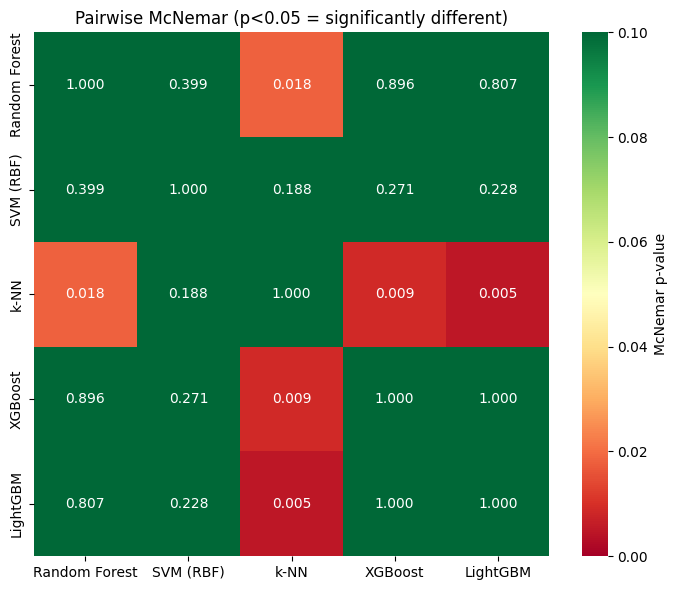

In [ ]:
sp=[r for r in rows if r['scheme']=='Spatial']; names=[r['model'] for r in sp]
preds={r['model']:r['pred'] for r in sp}
def mcnemar(a,b):
    c1=(a==y_enc); c2=(b==y_enc); n01=np.sum(c1&~c2); n10=np.sum(~c1&c2)
    if n01+n10==0: return 1.0
    return float(1-chi2.cdf((abs(n01-n10)-1)**2/(n01+n10),1))
m=len(names); Pm=np.ones((m,m))
for i in range(m):
    for j in range(i+1,m): Pm[i,j]=Pm[j,i]=mcnemar(preds[names[i]],preds[names[j]])
plt.figure(figsize=(7,6))
sns.heatmap(pd.DataFrame(Pm,index=names,columns=names),annot=True,fmt='.3f',cmap='RdYlGn',
            vmin=0,vmax=0.1,cbar_kws={'label':'McNemar p-value'})
plt.title('Pairwise McNemar (p<0.05 = significantly different)')
plt.xticks(rotation=0) # Set x-axis labels to be horizontal
plt.tight_layout(); plt.savefig('fig_mcnemar.png',dpi=300,bbox_inches='tight'); plt.show()
pd.DataFrame(Pm,index=names,columns=names).round(4).to_csv('hybrid_mcnemar.csv')

# 13. PERMUTATION FEATURE IMPORTANCE (by index)

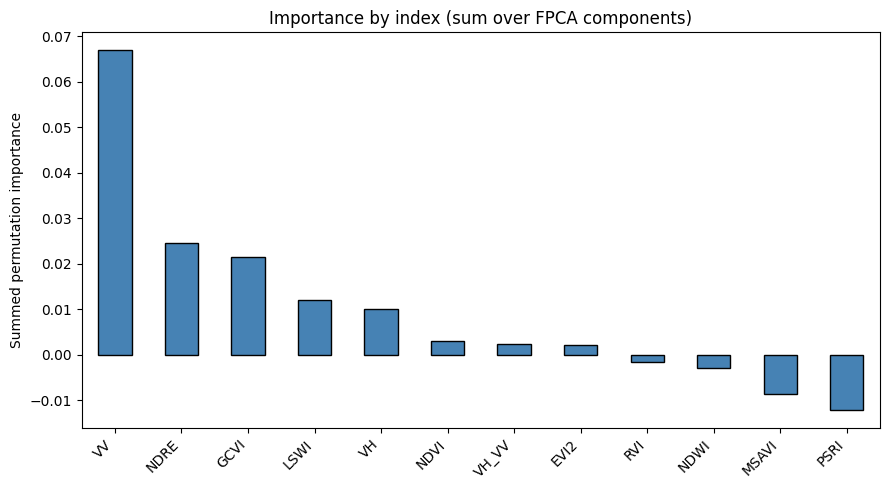

In [ ]:
gss=GroupShuffleSplit(n_splits=1,test_size=0.3,random_state=RANDOM_STATE)
tr,te=next(gss.split(X,y_enc,spatial_groups))
imp_model=models_factory()[best_sp['model']]; imp_model.fit(X[tr],y_enc[tr])
pi=permutation_importance(imp_model,X[te],y_enc[te],n_repeats=20,scoring='f1_macro',
                          random_state=RANDOM_STATE,n_jobs=-1)
imp=pd.Series(pi.importances_mean,index=feat_names)
by_index=imp.groupby(np.array(feat_index)).sum().sort_values(ascending=False)
plt.figure(figsize=(9,5)); by_index.plot.bar(color='steelblue',edgecolor='k')
plt.ylabel('Summed permutation importance'); plt.title('Importance by index (sum over FPCA components)')
plt.xticks(rotation=45,ha='right'); plt.tight_layout()
plt.savefig('fig_importance_by_index.png',dpi=300,bbox_inches='tight'); plt.show()
imp.sort_values(ascending=False).to_csv('hybrid_feature_importance.csv')

# 14. TUNE & RETRAIN BEST MODEL

In [ ]:
TUNE=best_sp['model']; print('Best spatial-CV model:',TUNE)
grids={'Random Forest':{'n_estimators':[300,600],'max_depth':[None,20],'min_samples_leaf':[1,3]},
       'XGBoost':{'n_estimators':[400,700],'max_depth':[4,6],'learning_rate':[0.03,0.06]},
       'LightGBM':{'n_estimators':[400,700],'num_leaves':[31,63],'learning_rate':[0.03,0.06]},
       'SVM (RBF)':{'svm__C':[3,10,30],'svm__gamma':['scale',0.01]},
       'k-NN':{'knn__n_neighbors':[5,7,11]}}
cv_iter=list(GroupKFold(n_splits=min(len(set(spatial_groups)),5)).split(X,y_enc,spatial_groups))
if TUNE in grids:
    gs=GridSearchCV(models_factory()[TUNE],grids[TUNE],scoring='f1_macro',cv=cv_iter,n_jobs=-1)
    gs.fit(X,y_enc); print('Best params:',gs.best_params_,'| tuned spatial F1=%.3f'%gs.best_score_)
    final_model=gs.best_estimator_
else:
    final_model=models_factory()[TUNE]
final_model.fit(X,y_enc); print('Deployed:',TUNE)

Best spatial-CV model: LightGBM
Best params: {'learning_rate': 0.03, 'n_estimators': 400, 'num_leaves': 31} | tuned spatial F1=0.835
Deployed: LightGBM


# 15. FULL-AREA CLASSIFICATION & AREA ESTIMATION

In [ ]:
MAP_YEAR='2022_23'; GRID_SCALE=10; m_s,m_e=SEASONS[MAP_YEAR]
crop_mask=DW.filterDate(m_s,m_e).filterBounds(roi).select('crops').mean().gt(0.4)
samp=crop_mask.selfMask().stratifiedSample(numPoints=4000,classBand='crops',
        region=roi.geometry(),scale=GRID_SCALE,geometries=True,seed=RANDOM_STATE)
grid_gdf=geemap.ee_to_gdf(samp)
grid_gdf['uid']=['g%d'%i for i in range(len(grid_gdf))]
grid_gdf['longitude']=grid_gdf.geometry.x; grid_gdf['latitude']=grid_gdf.geometry.y
print('grid cells:',len(grid_gdf))

grid cells: 4000


In [ ]:
fc=geemap.gdf_to_ee(grid_gdf[['uid','longitude','latitude','geometry']])
def pull_grid(coll,bands):
    size=coll.size().getInfo(); lst=coll.toList(size); rows=[]
    for i in range(size):
        im=ee.Image(lst.get(i)); ti=ee.Number(im.get('t_index')).getInfo()
        for ft in im.select(bands).reduceRegions(fc,ee.Reducer.mean(),GRID_SCALE).getInfo()['features']:
            p=ft['properties']; rec={'uid':p['uid'],'t':int(ti)}
            for b in bands: rec[b]=p.get(b)
            rows.append(rec)
    return pd.DataFrame(rows)
g2=pull_grid(composite_series(s2_collection(m_s,m_e),S2_INDICES,m_s,m_e),S2_INDICES)
g1=pull_grid(composite_series(s1_collection(m_s,m_e),S1_INDICES,m_s,m_e),S1_INDICES)
gts=pd.merge(g2,g1,on=['uid','t'],how='outer')
guids=sorted(gts['uid'].unique()); gcur={idx:np.full((len(guids),T),np.nan) for idx in ALL_INDICES}
for k,u in enumerate(guids):
    gg=gts[gts['uid']==u].sort_values('t')
    for idx in ALL_INDICES:
        lo,hi=INDEX_RANGE[idx]; tt=gg['t'].values; vv=np.clip(gg[idx].values.astype(float),lo,hi)
        ok=~np.isnan(vv)
        if ok.sum()>=2: gcur[idx][k]=np.interp(GRID,tt[ok],vv[ok],left=vv[ok][0],right=vv[ok][-1])
for idx in ALL_INDICES:
    cmn2=np.nanmean(gcur[idx],0); ii=np.where(np.isnan(gcur[idx])); gcur[idx][ii]=np.take(cmn2,ii[1])
gcur=smooth(gcur)
if HAS_SKFDA:
    Xg=np.hstack([FPCA(n_components=N_FPCA).fit_transform(FDataGrid(np.nan_to_num(gcur[idx]),grid_points=GRID))
                  for idx in ALL_INDICES])
else:
    Xg=np.hstack([np.column_stack([gcur[idx].mean(1),gcur[idx].max(1),gcur[idx].min(1),
                  gcur[idx].max(1)-gcur[idx].min(1),gcur[idx].sum(1),GRID[gcur[idx].argmax(1)]])
                  for idx in ALL_INDICES])
g_pred=le.inverse_transform(final_model.predict(Xg))
grid_pred=grid_gdf[grid_gdf['uid'].isin(guids)].copy(); grid_pred['pred_crop']=g_pred

Cropland (DW) 2022_23: 22,715 ha
           Area_ha  Share_%
pred_crop                  
Rice        7285.8     32.1
Mustard     5508.3     24.2
Wheat       5292.6     23.3
Maize       2118.2      9.3
Lentil      2112.5      9.3
Potato       397.5      1.8


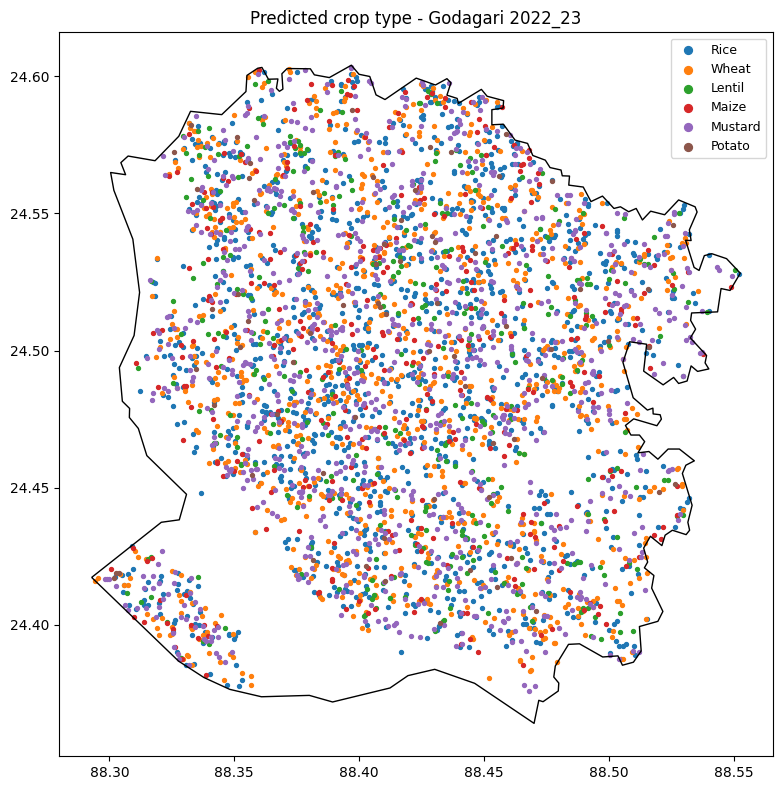

In [ ]:
crop_area_ha=(crop_mask.multiply(ee.Image.pixelArea())
    .reduceRegion(ee.Reducer.sum(),roi.geometry(),GRID_SCALE,maxPixels=1e10).get('crops').getInfo())/1e4
share=grid_pred['pred_crop'].value_counts(normalize=True)
area=(share*crop_area_ha).round(1).rename('Area_ha').to_frame(); area['Share_%']=(share*100).round(1).values
print(f'Cropland (DW) {MAP_YEAR}: {crop_area_ha:,.0f} ha'); print(area)
area.to_csv(f'hybrid_crop_area_{MAP_YEAR}.csv')

fig,ax=plt.subplots(figsize=(9,8))
for crop in CROPS:
    s=grid_pred[grid_pred['pred_crop']==crop]
    ax.scatter(s['longitude'],s['latitude'],s=8,color=palette[crop],label=crop)
roi_gdf.boundary.plot(ax=ax,color='k',lw=1); ax.legend(markerscale=2,fontsize=9)
ax.set_title(f'Predicted crop type - Godagari {MAP_YEAR}')
plt.tight_layout(); plt.savefig('fig_crop_map.png',dpi=300,bbox_inches='tight'); plt.show()